# Classical AI: Constraint Satisfaction Problems

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising CSPs for an exam or an interview.
>
> **What you will learn**
> - What a **constraint satisfaction problem (CSP)** is: variables, domains, and unary, binary and global constraints; the **constraint graph**
> - Four classic CSPs: **map colouring of Australia** (drawn), **Sudoku**, **N-Queens** and a small **university timetable**
> - **Backtracking search** with **MRV**, the **degree heuristic** and **LCV**
> - **Forward checking**, **arc consistency (AC-3)** with domains shrinking step by step, and **MAC**
> - A comparison table of assignments and backtracks for every method, including the "world's hardest Sudoku"
> - **Min-conflicts** local search solving **1,000-queens** (and 10,000) in a moment
> - **Tree-structured CSPs** and cutset conditioning, briefly, and how all this connects to real solvers and schedulers
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb). Helpful: depth-first search in [`02_uninformed_search.ipynb`](02_uninformed_search.ipynb), local search in [`04_local_search_and_optimization.ipynb`](04_local_search_and_optimization.ipynb), and backtracking in [`../dsa/10_backtracking.ipynb`](../dsa/10_backtracking.ipynb).
>
> **Time needed:** about 2 hours (the code runs in under a minute).
>
> **Runs on:** CPU, no API key. Only Python, numpy, pandas, matplotlib and networkx (OR-Tools is mentioned as an optional extra and is not needed).
>
> **Optional track:** this notebook is part of the university-level fundamentals track; it is recommended for BS/MS AI students and for interview prep. You can skip it and still follow the rest of the repo.

## Explained simply

Many everyday puzzles are about making choices that obey rules. A school timetable: every lesson needs a time and a room, and no teacher can be in two places at once. A wedding seating plan: every guest needs a table, and some guests must not sit together. A Sudoku: every empty square needs a digit, and no digit may repeat in a row, column or box. A **constraint satisfaction problem** is exactly this: a list of things to decide, the options for each, and the rules. Instead of trying every combination (far too many), a computer fills in one choice at a time, checks the rules, and goes back as soon as something breaks. Even better, after each choice it crosses out options that are now impossible, the way you pencil in and erase candidates in Sudoku. Real schedulers for airlines, hospitals and cloud computers work on the same idea.

**Tiny example.** Three countries, A, B and C, all touch each other, and neighbours must have different colours. With only red and green: A = red, B = green, and C touches both, so C has no colour left: impossible. Add blue: A = red, B = green, C = blue. Solved, and we only had to look at a handful of options.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Constraint satisfaction problem | choices plus rules that the choices must obey | Sudoku, timetables, staff rosters |
| Backtracking | fill in one choice at a time; undo the last choice when stuck | solving a maze or a puzzle by hand |
| Constraint propagation | cross out options that can no longer work | pencil marks in Sudoku, cloud job schedulers |

## 1. What is a CSP?

*In plain words: a problem described by "what must be decided", "what each decision can be" and "which combinations are allowed".*

In ordinary search a state is a black box. In a **constraint satisfaction problem** a state has a known structure, and that structure lets general-purpose algorithms prune enormous parts of the search space.

A CSP has three parts (AIMA 4th ed., Section 6.1):
- **Variables** $X = \{X_1, \dots, X_n\}$, the things to decide.
- **Domains** $D = \{D_1, \dots, D_n\}$, the allowed values of each variable.
- **Constraints** $C$, each one a *scope* (the variables it involves) and a *relation* (the allowed value combinations).

| Term | Meaning |
|---|---|
| **Assignment** | values given to some or all variables, e.g. {WA = red, NT = green} |
| **Consistent** assignment | breaks no constraint |
| **Complete** assignment | every variable has a value |
| **Solution** | a consistent and complete assignment |
| **Partial** assignment | only some variables have values |

Kinds of constraints:

| Kind | Involves | Example |
|---|---|---|
| **Unary** | one variable | "SA is not green"; "Ethics must be on Tuesday" |
| **Binary** | two variables | "WA ≠ NT" (neighbours get different colours) |
| **Global** (higher-order) | any number | **Alldiff**$(X_1, \dots, X_9)$: all different, e.g. a Sudoku row |
| **Preference** (soft) | any | "Prof. Lee prefers mornings": costs, not rules (constrained optimisation) |

A global constraint such as Alldiff over $k$ variables can be rewritten as $\binom{k}{2}$ binary "≠" constraints, so in this notebook every constraint becomes binary. The **constraint graph** has one node per variable and an edge between any two variables that share a constraint.

**Why bother?** Search algorithms can look *inside* the state: as soon as a partial assignment breaks a constraint, every completion of it can be discarded at once. With 9 Sudoku digits for 60 empty cells, there are $9^{60} \approx 1.8 \times 10^{57}$ complete assignments, yet a good CSP solver finishes in a fraction of a second.

In [1]:
# Setup: imports used throughout the notebook
import math, random, time, itertools
from collections import Counter, deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import networkx as nx

random.seed(0); np.random.seed(0)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)
NOTEBOOK_START = time.time()

class CSP:
    # A CSP with binary constraints (AIMA-style).
    #   variables  : list of variable names (any hashable values)
    #   domains    : dict variable -> list of allowed values
    #   neighbours : dict variable -> list of variables it shares a constraint with
    #   constraint : function(A, a, B, b) -> True if A=a and B=b are compatible
    def __init__(self, variables, domains, neighbours, constraint):
        self.variables = list(variables)
        self.domains = {v: list(domains[v]) for v in self.variables}
        self.neighbours = {v: list(neighbours[v]) for v in self.variables}
        self._constraint = constraint
        self.checks = 0                                 # how many constraint checks we did

    def constraint(self, A, a, B, b):
        self.checks += 1
        return self._constraint(A, a, B, b)

    def n_binary_constraints(self):
        return sum(len(ns) for ns in self.neighbours.values()) // 2

    def is_solution(self, assignment):
        # complete and consistent? (checked independently of any solver)
        return (set(assignment) == set(self.variables) and
                all(assignment[v] in self.domains[v] for v in self.variables) and
                all(self._constraint(A, assignment[A], B, assignment[B])
                    for A in self.variables for B in self.neighbours[A]))

def different(A, a, B, b):
    return a != b
print("CSP class ready")

CSP class ready


## 2. Four example CSPs

*In plain words: the same three ingredients (variables, domains, constraints) describe very different puzzles.*

### 2.1 Map colouring: Australia

Colour each state or territory of Australia red, green or blue so that neighbours get different colours (AIMA's running example).

- Variables: WA, NT, SA, Q, NSW, V, T
- Domains: {red, green, blue} for each
- Constraints: WA ≠ NT, WA ≠ SA, NT ≠ SA, NT ≠ Q, SA ≠ Q, SA ≠ NSW, SA ≠ V, Q ≠ NSW, NSW ≠ V (9 binary constraints; Tasmania, T, has no neighbours)

In [2]:
AUS_VARS = ["WA", "NT", "SA", "Q", "NSW", "V", "T"]
AUS_EDGES = [("WA", "NT"), ("WA", "SA"), ("NT", "SA"), ("NT", "Q"), ("SA", "Q"),
             ("SA", "NSW"), ("SA", "V"), ("Q", "NSW"), ("NSW", "V")]

def make_map_csp(variables, edges, colours):
    neighbours = {v: [] for v in variables}
    for a, b in edges:
        neighbours[a].append(b); neighbours[b].append(a)
    return CSP(variables, {v: colours for v in variables}, neighbours, different)

COLOURS = ["red", "green", "blue"]
australia = make_map_csp(AUS_VARS, AUS_EDGES, COLOURS)

# Brute force: try all 3^7 = 2,187 complete assignments and count the solutions
brute = [dict(zip(AUS_VARS, vals)) for vals in itertools.product(COLOURS, repeat=7)]
aus_solutions = [a for a in brute if australia.is_solution(a)]
print("binary constraints:", australia.n_binary_constraints())
print("solutions found by brute force:", len(aus_solutions), "out of", len(brute), "complete assignments")
assert len(aus_solutions) == 18

binary constraints: 9
solutions found by brute force: 18 out of 2187 complete assignments


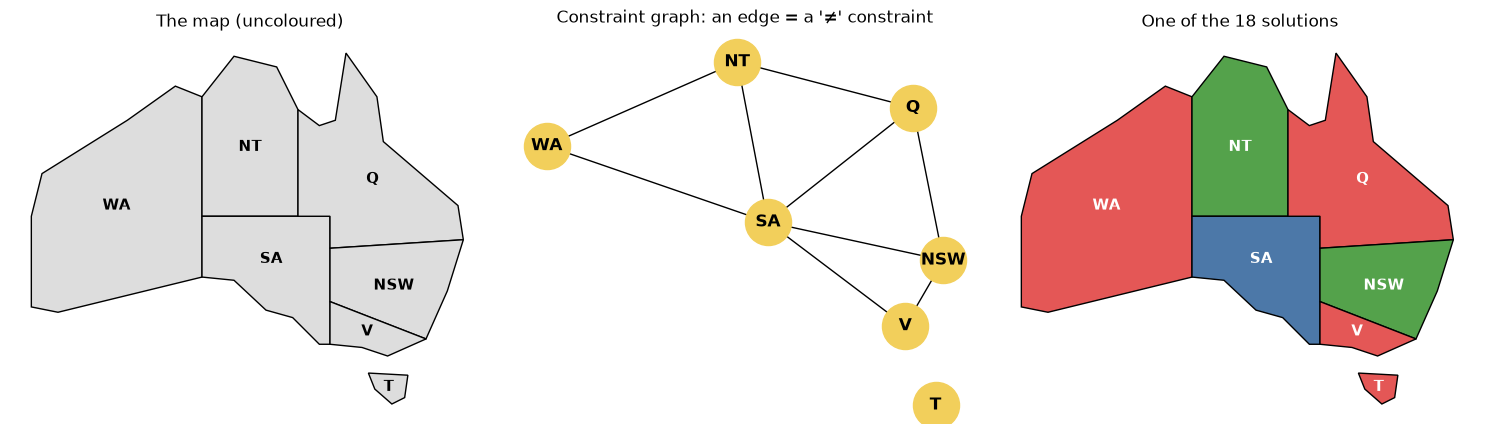

In [3]:
# Rough outlines of the states (longitude, latitude), good enough for a picture
AUS_SHAPES = {
    "WA": [(113, -34.5), (115.5, -35), (129, -31.7), (129, -14.8), (126.5, -13.8), (122, -17), (114, -22), (113, -26)],
    "NT": [(129, -26), (138, -26), (138, -16), (136, -12), (132, -11), (129, -14.8)],
    "SA": [(129, -26), (141, -26), (141, -38), (140, -38), (137.5, -35.5), (135, -34.8), (132, -32), (129, -31.7)],
    "Q":  [(138, -26), (141, -26), (141, -29), (153.5, -28.2), (153, -25), (146, -19), (145.4, -14.8),
           (142.5, -10.7), (141.5, -17), (140, -17.5), (138, -16)],
    "NSW": [(141, -29), (153.5, -28.2), (152, -33), (150, -37.5), (141, -34)],
    "V":  [(141, -34), (150, -37.5), (146.4, -39.1), (144, -38.3), (141, -38)],
    "T":  [(144.6, -40.7), (148.3, -40.9), (148.0, -43.0), (146.8, -43.6), (145.2, -42.2)],
}
CENTRES = {"WA": (121, -25), "NT": (133.5, -19.5), "SA": (135.5, -30), "Q": (145, -22.5),
           "NSW": (147, -32.5), "V": (144.5, -36.8), "T": (146.5, -42)}
PALETTE = {"red": "#e45756", "green": "#54a24b", "blue": "#4c78a8", None: "#dddddd"}

def draw_australia(ax, colouring=None, title=""):
    for state, pts in AUS_SHAPES.items():
        colour = PALETTE[(colouring or {}).get(state)]
        ax.add_patch(Polygon(pts, closed=True, facecolor=colour, edgecolor="black", lw=1))
        ax.text(*CENTRES[state], state, ha="center", va="center", fontsize=11, fontweight="bold", color="white" if colouring else "black")
    ax.set_xlim(111, 156); ax.set_ylim(-45, -9); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
draw_australia(axes[0], None, "The map (uncoloured)")
G = nx.Graph(AUS_EDGES); G.add_node("T")
nx.draw(G, pos=CENTRES, ax=axes[1], with_labels=True, node_color="#f2cf5b", node_size=1100, font_weight="bold")
axes[1].set_title("Constraint graph: an edge = a '≠' constraint"); axes[1].set_aspect("equal")
draw_australia(axes[2], aus_solutions[0], "One of the 18 solutions")
plt.tight_layout(); plt.show()

**What just happened?** The brute force tried all $3^7 = 2{,}187$ complete assignments and found **18 solutions** (6 ways to colour the mainland, since the WA-NT-SA-Q-NSW-V part is fixed once three mutually adjacent states are coloured, times 3 colours for Tasmania). The constraint graph shows the structure: SA touches five states, Tasmania is disconnected. A solver can exploit both facts.

### 2.2 Sudoku

- 81 variables, one per cell; domain {1..9} (a given cell's domain is just its given digit: a **unary constraint**).
- 27 **Alldiff** constraints (9 rows, 9 columns, 9 boxes). Each cell has 20 **peers** (8 in its row, 8 in its column, 4 more in its box), giving $81 \times 20 / 2 = 810$ binary "≠" constraints.

In [4]:
def sudoku_csp(grid):
    # grid: string of 81 characters, '0' or '.' for empty
    cells = [(r, c) for r in range(9) for c in range(9)]
    peers = {}
    for r, c in cells:
        ps = {(r, k) for k in range(9)} | {(k, c) for k in range(9)} | \
             {(3 * (r // 3) + i, 3 * (c // 3) + j) for i in range(3) for j in range(3)}
        ps.discard((r, c))
        peers[(r, c)] = sorted(ps)                                   # sorted: a fixed order
    domains = {}
    for (r, c), ch in zip(cells, grid):
        domains[(r, c)] = [int(ch)] if ch not in "0." else list(range(1, 10))   # unary constraint
    return CSP(cells, domains, peers, different)

def sudoku_valid(grid, assignment):
    # independent checker: rows, columns and boxes are permutations of 1..9 and givens are kept
    g = [[assignment[(r, c)] for c in range(9)] for r in range(9)]
    units = [g[r] for r in range(9)] + [[g[r][c] for r in range(9)] for c in range(9)] + \
            [[g[3 * br + i][3 * bc + j] for i in range(3) for j in range(3)] for br in range(3) for bc in range(3)]
    givens_kept = all(ch in "0." or int(ch) == g[i // 9][i % 9] for i, ch in enumerate(grid))
    return all(sorted(u) == list(range(1, 10)) for u in units) and givens_kept

def show_sudoku(assignment_or_grid):
    if isinstance(assignment_or_grid, str):
        vals = [ch if ch not in "0." else "." for ch in assignment_or_grid]
    else:
        vals = [str(assignment_or_grid[(r, c)]) for r in range(9) for c in range(9)]
    lines = []
    for r in range(9):
        row = vals[9 * r:9 * r + 9]
        lines.append(" ".join(row[0:3]) + " | " + " ".join(row[3:6]) + " | " + " ".join(row[6:9]))
        if r in (2, 5):
            lines.append("------+-------+------")
    return "\n".join(lines)

EASY_SUDOKU = "003020600900305001001806400008102900700000008006708200002609500800203009005010300"
HARD_SUDOKU = "800000000003600000070090200050007000000045700000100030001000068008500010090000400"  # Inkala, 2012
HARD_SOLUTION = "812753649943682175675491283154237896369845721287169534521974368438526917796318452"

s = sudoku_csp(EASY_SUDOKU)
print("variables:", len(s.variables), "| binary constraints:", s.n_binary_constraints())
assert s.n_binary_constraints() == 810 and all(len(p) == 20 for p in s.neighbours.values())
print(show_sudoku(EASY_SUDOKU))

variables: 81 | binary constraints: 810
. . 3 | . 2 . | 6 . .
9 . . | 3 . 5 | . . 1
. . 1 | 8 . 6 | 4 . .
------+-------+------
. . 8 | 1 . 2 | 9 . .
7 . . | . . . | . . 8
. . 6 | 7 . 8 | 2 . .
------+-------+------
. . 2 | 6 . 9 | 5 . .
8 . . | 2 . 3 | . . 9
. . 5 | . 1 . | 3 . .


### 2.3 N-Queens

- Variables: $Q_0, \dots, Q_{N-1}$, the row of the queen in column $i$ (one queen per column is built into the formulation).
- Domain: $\{0, \dots, N-1\}$.
- Constraint between every pair $Q_i, Q_j$: $Q_i \ne Q_j$ (different rows) and $|Q_i - Q_j| \ne |i - j|$ (different diagonals). The constraint graph is complete: $\binom{N}{2}$ constraints.

### 2.4 A small university timetable

Six courses must each get a **(time slot, room)** pair. Four slots (Mon 9:00, Mon 11:00, Tue 9:00, Tue 11:00) and two rooms (R1 seats 120, R2 seats 40), so each domain has 8 values.

| Course | Students | Lecturer | Year group |
|---|---|---|---|
| AI | 100 | Khan | Y3 |
| ML | 90 | Khan | Y3 |
| DSA | 60 | Lee | Y2 |
| DBMS | 35 | Lee | Y2 |
| Maths | 110 | Patel | Y1 |
| Ethics | 30 | Patel | Y3 |

Constraints:
- **Unary:** the room must be big enough; Khan is not available on Monday at 9:00; Ethics must be on Tuesday.
- **Binary:** two courses cannot use the same room at the same time; two courses with the same lecturer cannot be at the same time; two courses for the same year group cannot be at the same time.

In [5]:
def queens_csp(n):
    cols = list(range(n))
    return CSP(cols, {c: list(range(n)) for c in cols}, {c: [d for d in cols if d != c] for c in cols},
               lambda A, a, B, b: a != b and abs(a - b) != abs(A - B))

SLOTS = ["Mon 9:00", "Mon 11:00", "Tue 9:00", "Tue 11:00"]
ROOMS = {"R1": 120, "R2": 40}
COURSES = {  # name: (students, lecturer, year group)
    "AI": (100, "Khan", "Y3"), "ML": (90, "Khan", "Y3"), "DSA": (60, "Lee", "Y2"),
    "DBMS": (35, "Lee", "Y2"), "Maths": (110, "Patel", "Y1"), "Ethics": (30, "Patel", "Y3"),
}

def timetable_csp():
    variables = list(COURSES)
    domains = {}
    for course, (students, lecturer, _) in COURSES.items():
        values = []
        for slot in SLOTS:
            for room, capacity in ROOMS.items():
                if students > capacity:                       # unary: room too small
                    continue
                if lecturer == "Khan" and slot == "Mon 9:00":  # unary: lecturer unavailable
                    continue
                if course == "Ethics" and not slot.startswith("Tue"):   # unary: must be on Tuesday
                    continue
                values.append((slot, room))
        domains[course] = values
    def compatible(A, a, B, b):
        (slot_a, room_a), (slot_b, room_b) = a, b
        if slot_a != slot_b:
            return True                                       # different times never clash
        same_lecturer = COURSES[A][1] == COURSES[B][1]
        same_group = COURSES[A][2] == COURSES[B][2]
        return room_a != room_b and not same_lecturer and not same_group
    neighbours = {v: [u for u in variables if u != v] for v in variables}
    return CSP(variables, domains, neighbours, compatible)

tt = timetable_csp()
print("domain sizes after the unary constraints:", {v: len(d) for v, d in tt.domains.items()})
# brute force over the (already unary-filtered) domains
tt_solutions = [dict(zip(tt.variables, vals)) for vals in itertools.product(*(tt.domains[v] for v in tt.variables))
                if tt.is_solution(dict(zip(tt.variables, vals)))]
print("timetable solutions found by brute force:", len(tt_solutions))

domain sizes after the unary constraints: {'AI': 3, 'ML': 3, 'DSA': 4, 'DBMS': 8, 'Maths': 4, 'Ethics': 4}
timetable solutions found by brute force: 12


**What just happened?** Applying the unary constraints first (**node consistency**) already shrank the domains: AI and ML can only use R1 and not Monday 9:00, so each has 3 values; Ethics only has the 4 Tuesday options. The brute force then counted every valid timetable, which we will use to check the solvers.

## 3. Backtracking search

*In plain words: assign one variable at a time, and the moment a rule is broken, undo the last choice and try the next option.*

**Backtracking search** is depth-first search over partial assignments that:
1. assigns **one variable per level** (the order of variables does not change the set of solutions, so we never branch on "which variable");
2. checks constraints **immediately**, and backs up as soon as the current partial assignment is inconsistent.

```
function BACKTRACK(assignment):
    if assignment is complete: return assignment
    var <- SELECT-UNASSIGNED-VARIABLE()                 # which variable next?   (MRV, degree)
    for value in ORDER-DOMAIN-VALUES(var):              # which value first?     (LCV)
        if value is consistent with assignment:
            add {var = value}
            inferences <- INFERENCE(var, value)         # look ahead             (FC, MAC)
            if inferences did not wipe out a domain:
                result <- BACKTRACK(assignment)
                if result != failure: return result
            undo {var = value} and the inferences       # <- a "backtrack"
    return failure
```

**Heuristics** (all from AIMA Section 6.3):

| Heuristic | Rule | Intuition |
|---|---|---|
| **MRV** (minimum remaining values, "fail-first") | pick the variable with the fewest legal values left | if a variable is about to fail, find out now, not after a lot of wasted work |
| **Degree heuristic** | break MRV ties by the variable involved in the most constraints with unassigned variables | assigning it constrains the most others |
| **LCV** (least constraining value, "fail-last") | try first the value that rules out the fewest values in neighbours' domains | keep as many options open as possible for the rest |

Variables: fail-first. Values: fail-last. (We need *every* variable assigned, so we want to discover dead ends early, but only *one* value per variable has to work, so we try the most promising first.)

We count two things: **assignments** (how many times a value was assigned to a variable) and **backtracks** (how many times an assignment had to be undone because its subtree failed).

In [6]:
class BudgetExceeded(Exception):
    pass

def backtracking_search(csp, var_order="static", value_order="natural", inference="none", max_assignments=200_000):
    # Returns (solution or None, stats). inference: "none", "fc" (forward checking) or "mac" (maintain arc consistency)
    csp.checks = 0
    domains = {v: list(csp.domains[v]) for v in csp.variables}   # current domains (shrink during inference)
    assignment = {}
    stats = Counter()
    rank = {v: {x: i for i, x in enumerate(csp.domains[v])} for v in csp.variables}   # original value order

    def consistent(var, val):
        return all(csp.constraint(var, val, n, assignment[n]) for n in csp.neighbours[var] if n in assignment)

    def legal_count(v):
        if inference != "none":                                  # inference keeps domains consistent already
            return len(domains[v])
        return sum(1 for x in domains[v] if consistent(v, x))

    def select_variable():
        unassigned = [v for v in csp.variables if v not in assignment]
        if var_order == "static":
            return unassigned[0]                                 # first in the fixed order
        if var_order == "mrv":
            return min(unassigned, key=legal_count)              # fewest legal values
        if var_order == "mrv+degree":                            # tie-break: most unassigned neighbours
            return min(unassigned, key=lambda v: (legal_count(v),
                                                  -sum(1 for n in csp.neighbours[v] if n not in assignment)))

    def order_values(var):
        if value_order == "natural":                             # original order (undoing may have reordered)
            return sorted(domains[var], key=rank[var].get)
        def ruled_out(val):                                      # LCV: values removed from neighbours
            return sum(1 for n in csp.neighbours[var] if n not in assignment
                       for b in domains[n] if not csp.constraint(var, val, n, b))
        return sorted(sorted(domains[var], key=rank[var].get), key=ruled_out)   # ties: original order

    def forward_check(var, val, removals):
        for n in csp.neighbours[var]:
            if n in assignment:
                continue
            for b in list(domains[n]):
                if not csp.constraint(var, val, n, b):
                    domains[n].remove(b); removals.append((n, b))
            if not domains[n]:
                return False                                     # a domain was wiped out
        return True

    def infer(var, val, removals):
        for other in list(domains[var]):                         # var's domain becomes {val}
            if other != val:
                domains[var].remove(other); removals.append((var, other))
        if inference == "fc":
            return forward_check(var, val, removals)
        if inference == "mac":
            arcs = [(n, var) for n in csp.neighbours[var] if n not in assignment]
            return ac3(csp, domains, arcs, removals)
        return True

    def backtrack():
        if len(assignment) == len(csp.variables):
            return dict(assignment)
        var = select_variable()
        for val in order_values(var):
            if consistent(var, val):
                assignment[var] = val
                stats["assignments"] += 1
                if stats["assignments"] > max_assignments:
                    raise BudgetExceeded
                removals = []
                if infer(var, val, removals):
                    res = backtrack()
                    if res is not None:
                        return res
                for v, x in removals:                            # undo the inferences
                    domains[v].append(x)
                del assignment[var]
                stats["backtracks"] += 1
        return None

    try:
        solution = backtrack()
        stats["solved"] = solution is not None
    except BudgetExceeded:
        solution, stats["solved"] = None, False
        stats["gave up"] = True
    stats["constraint checks"] = csp.checks
    return solution, stats

def revise(csp, domains, xi, xj, removals=None):
    # remove values of xi that have no supporting value in xj; return True if anything was removed
    revised = False
    for x in list(domains[xi]):
        if not any(csp.constraint(xi, x, xj, y) for y in domains[xj]):
            domains[xi].remove(x)
            if removals is not None:
                removals.append((xi, x))
            revised = True
    return revised

def ac3(csp, domains, arcs=None, removals=None, trace=None):
    # AC-3: make every arc (xi, xj) consistent. Returns False if some domain becomes empty.
    queue = deque(arcs if arcs is not None else [(xi, xj) for xi in csp.variables for xj in csp.neighbours[xi]])
    in_queue = set(queue)
    while queue:
        xi, xj = queue.popleft(); in_queue.discard((xi, xj))
        before = list(domains[xi])
        if revise(csp, domains, xi, xj, removals):
            if trace is not None:
                trace.append({"arc": f"{xi} -> {xj}", "removed from X_i": [x for x in before if x not in domains[xi]],
                              "D(X_i) now": list(domains[xi])})
            if not domains[xi]:
                return False
            for xk in csp.neighbours[xi]:                        # neighbours of xi must be re-checked
                if xk != xj and (xk, xi) not in in_queue:
                    queue.append((xk, xi)); in_queue.add((xk, xi))
    return True

sol, st = backtracking_search(make_map_csp(AUS_VARS, AUS_EDGES, COLOURS))
print("plain backtracking on Australia:", sol, dict(st))
assert australia.is_solution(sol)

plain backtracking on Australia: {'WA': 'red', 'NT': 'green', 'SA': 'blue', 'Q': 'red', 'NSW': 'green', 'V': 'red', 'T': 'red'} {'assignments': 7, 'solved': True, 'constraint checks': 15}


**What just happened?** Plain backtracking coloured Australia. Because the variables are listed in a sensible order (WA, NT, SA, Q, ...), it needed only 7 assignments and no backtracks. Now let us watch a case where things go wrong, and see how **inference** helps.

**Complexity of backtracking:** in the worst case $O(d^n)$ for $n$ variables with $d$ values (it can explore the whole tree), and $O(n)$ space for the recursion plus the domains. CSPs are NP-complete in general (3-colouring and SAT are special cases), so no algorithm is known to be polynomial in the worst case; heuristics and inference make typical cases fast. See [`../advanced_algorithms/02_np_completeness_and_reductions.ipynb`](../advanced_algorithms/02_np_completeness_and_reductions.ipynb).

## 4. Inference: forward checking, AC-3 and MAC

*In plain words: after each choice, cross out the options that just became impossible, so dead ends show up early.*

**Forward checking (FC):** after assigning $X = v$, delete from every unassigned neighbour $Y$ the values inconsistent with $v$. If a domain becomes empty, backtrack immediately.

**Arc consistency:** a directed arc $X_i \to X_j$ is **arc-consistent** if *every* value in $D_i$ has *some* supporting value in $D_j$ that satisfies the constraint. **AC-3** (Mackworth, 1977) puts all arcs in a queue; it **revises** each arc (removing unsupported values) and, whenever $D_i$ shrinks, re-queues the arcs $X_k \to X_i$ pointing into $X_i$ (their support may have disappeared).

**MAC (Maintaining Arc Consistency):** after each assignment $X = v$, run AC-3 starting from the arcs $Y \to X$ for the unassigned neighbours $Y$. It propagates further than forward checking.

**Worked example by hand** (AIMA Figure 6.7). Assign WA = red, then Q = green.

| | WA | NT | SA | Q | NSW | V | T |
|---|---|---|---|---|---|---|---|
| start | RGB | RGB | RGB | RGB | RGB | RGB | RGB |
| WA = red, FC | **R** | GB | GB | RGB | RGB | RGB | RGB |
| Q = green, FC | R | B | B | **G** | RB | RGB | RGB |

Forward checking stops here: no domain is empty. But NT and SA are neighbours and both can only be blue, so this partial assignment is already hopeless. **Arc consistency notices**: revising NT → SA removes blue from NT (there is no other value left in SA to support it), and NT's domain becomes empty.

**Complexity of AC-3:** with $c$ binary constraints (so $2c$ arcs) and domains of size at most $d$: each arc can be re-queued at most $d$ times (once per value deleted from its target), and revising an arc costs $O(d^2)$, so $O(c\,d^3)$ time in the worst case, $O(c)$ extra space for the queue.

In [7]:
# Forward checking vs AC-3 after WA = red, Q = green
aus = make_map_csp(AUS_VARS, AUS_EDGES, COLOURS)
doms = {v: list(COLOURS) for v in AUS_VARS}
doms["WA"], doms["Q"] = ["red"], ["green"]
# forward checking from the two assignments
for var in ("WA", "Q"):
    for n in aus.neighbours[var]:
        doms[n] = [b for b in doms[n] if b != doms[var][0]]
fc_view = {v: "".join(c[0].upper() for c in doms[v]) for v in AUS_VARS}
print("after forward checking:", fc_view, "-> no empty domain, FC does not see the problem")

trace = []
ok = ac3(aus, doms, trace=trace)
display(pd.DataFrame(trace))
print("AC-3 result:", "consistent" if ok else "INCONSISTENT: a domain was wiped out")
assert not ok

after forward checking: {'WA': 'R', 'NT': 'B', 'SA': 'B', 'Q': 'G', 'NSW': 'RB', 'V': 'RGB', 'T': 'RGB'} -> no empty domain, FC does not see the problem


,arc,removed from X_i,D(X_i) now
0,NT -> SA,[blue],[]


AC-3 result: INCONSISTENT: a domain was wiped out


**What just happened?** Each row of the table is one revision that removed something. Forward checking left NT = {blue} and SA = {blue} and saw nothing wrong; AC-3 revised the arc between them, deleted blue, and reported failure before any further search. MAC does this at every node of the search tree.

Now let us watch AC-3 shrink all 81 Sudoku domains *before any search at all*.

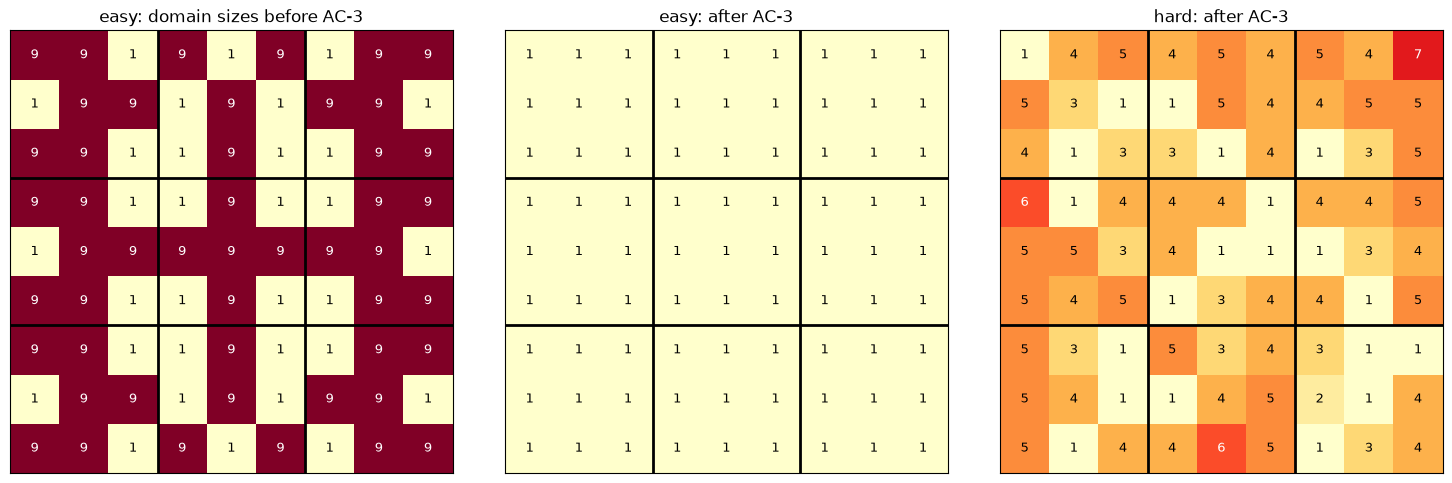

,puzzle,givens,total values before,total values after AC-3,cells fixed after AC-3,solved by AC-3 alone,constraint checks
0,easy,32,473,81,81,True,10344
1,hard,21,561,275,21,False,11611


In [8]:
def domain_sizes(csp_domains):
    return np.array([[len(csp_domains[(r, c)]) for c in range(9)] for r in range(9)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
rows = []
for ax_pair, (name, grid) in zip([(axes[0], axes[1]), (None, axes[2])], [("easy", EASY_SUDOKU), ("hard", HARD_SUDOKU)]):
    sc = sudoku_csp(grid)
    before = domain_sizes(sc.domains)
    doms = {v: list(d) for v, d in sc.domains.items()}
    sc.checks = 0
    ok = ac3(sc, doms)
    after = domain_sizes(doms)
    rows.append({"puzzle": name, "givens": int((before == 1).sum()), "total values before": int(before.sum()),
                 "total values after AC-3": int(after.sum()), "cells fixed after AC-3": int((after == 1).sum()),
                 "solved by AC-3 alone": bool((after == 1).all()), "constraint checks": sc.checks})
    if name == "easy":
        solved_by_ac3 = {v: d[0] for v, d in doms.items()}
    for ax, data, title in [(ax_pair[0], before, f"{name}: domain sizes before AC-3"), (ax_pair[1], after, f"{name}: after AC-3")]:
        if ax is None:
            continue
        ax.imshow(data, cmap="YlOrRd", vmin=1, vmax=9)
        for r in range(9):
            for c in range(9):
                ax.text(c, r, data[r, c], ha="center", va="center", fontsize=9, color="white" if data[r, c] >= 6 else "black")
        for k in (2.5, 5.5):
            ax.axhline(k, color="black", lw=2); ax.axvline(k, color="black", lw=2)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))
assert rows[0]["solved by AC-3 alone"] and sudoku_valid(EASY_SUDOKU, solved_by_ac3)

**What just happened?** Each number is how many digits are still possible in that cell (yellow = few, red = many). For the **easy** puzzle, AC-3 alone reduced every domain to a single digit: the puzzle is solved without any search (and the result passes the independent Sudoku checker). For the **hard** puzzle (right panel), AC-3 removes some candidates but most cells keep several, so search is still needed. Many newspaper Sudokus are "AC-3 easy"; puzzles rated hard need search or stronger reasoning.

> ⚠️ **Common mistake:** thinking that arc consistency means "solvable". Arc consistency only looks at *pairs* of variables. Three variables with domains {1, 2} and Alldiff are pairwise arc-consistent (each value has a different partner) but obviously unsolvable: three variables cannot take three different values from a set of two. Global reasoning (here, counting values versus variables) catches it.

In [9]:
trio = CSP(["X", "Y", "Z"], {v: [1, 2] for v in "XYZ"}, {"X": ["Y", "Z"], "Y": ["X", "Z"], "Z": ["X", "Y"]}, different)
doms = {v: [1, 2] for v in "XYZ"}
print("AC-3 says consistent:", ac3(trio, doms), "| domains after AC-3:", doms)
print("solutions by brute force:", sum(trio.is_solution(dict(zip("XYZ", vals))) for vals in itertools.product([1, 2], repeat=3)))

AC-3 says consistent: True | domains after AC-3: {'X': [1, 2], 'Y': [1, 2], 'Z': [1, 2]}
solutions by brute force: 0


## 5. Comparing the methods

*In plain words: same puzzles, six solvers, and we count how much work each one does.*

We run six configurations on six problems. Each run is capped at 50,000 assignments; a capped run is shown as "> 50,000". Every solution is checked with the independent `is_solution` checker.

For Australia we deliberately list the variables in a bad order (WA, NSW, T, V, Q, NT, SA), found by trying all $7! = 5{,}040$ orders and keeping the one where plain backtracking struggles most.

In [10]:
METHODS = {
    "BT":                   dict(var_order="static", value_order="natural", inference="none"),
    "BT + MRV":             dict(var_order="mrv", value_order="natural", inference="none"),
    "FC":                   dict(var_order="static", value_order="natural", inference="fc"),
    "FC + MRV":             dict(var_order="mrv", value_order="natural", inference="fc"),
    "FC + MRV/degree + LCV": dict(var_order="mrv+degree", value_order="lcv", inference="fc"),
    "MAC + MRV + LCV":      dict(var_order="mrv", value_order="lcv", inference="mac"),
}
# Australia in a deliberately bad order: SA, the most constrained state, comes last and T sits in the middle
BAD_ORDER = ["WA", "NSW", "T", "V", "Q", "NT", "SA"]
PROBLEMS = {
    "Australia (bad order)": lambda: make_map_csp(BAD_ORDER, AUS_EDGES, COLOURS),
    "8-queens": lambda: queens_csp(8),
    "16-queens": lambda: queens_csp(16),
    "timetable": timetable_csp,
    "easy Sudoku": lambda: sudoku_csp(EASY_SUDOKU),
    "hard Sudoku": lambda: sudoku_csp(HARD_SUDOKU),
}
results = []
solutions = {}
for pname, make in PROBLEMS.items():
    for mname, kwargs in METHODS.items():
        if pname == "hard Sudoku" and mname == "BT + MRV":
            # MRV without inference re-checks every value of every cell against the assignment at each step:
            # correct, but too slow in pure Python on this puzzle, so we skip it here
            results.append({"problem": pname, "method": mname, "assignments": "not run",
                            "backtracks": "not run", "constraint checks": "", "ms": "", "solved": "not run"})
            continue
        csp = make()
        t0 = time.perf_counter()
        sol, st = backtracking_search(csp, max_assignments=50_000, **kwargs)
        ms = 1000 * (time.perf_counter() - t0)
        if sol is not None:
            assert csp.is_solution(sol)                            # independent validity check
            solutions[(pname, mname)] = sol
        results.append({"problem": pname, "method": mname,
                        "assignments": st["assignments"] if sol else f"> {st['assignments'] - 1:,}",
                        "backtracks": st["backtracks"] if sol else "", "constraint checks": st["constraint checks"],
                        "ms": round(ms, 1), "solved": "yes" if sol else "gave up"})
cmp_df = pd.DataFrame(results)
display(cmp_df.pivot(index="method", columns="problem", values="assignments")[list(PROBLEMS)].loc[list(METHODS)])
display(cmp_df.pivot(index="method", columns="problem", values="backtracks")[list(PROBLEMS)].loc[list(METHODS)])

problem,Australia (bad order),8-queens,16-queens,timetable,easy Sudoku,hard Sudoku
method,,,,,,
BT,41,113,10052,15,"> 50,000","> 50,000"
BT + MRV,7,75,44,8,81,not run
FC,35,88,7560,15,489,"> 50,000"
FC + MRV,7,75,44,8,81,10122
FC + MRV/degree + LCV,7,39,332,8,81,4262
MAC + MRV + LCV,7,14,128,6,81,3730


problem,Australia (bad order),8-queens,16-queens,timetable,easy Sudoku,hard Sudoku
method,,,,,,
BT,34,105,10036,9,,
BT + MRV,0,67,28,2,0,not run
FC,28,80,7544,9,408,
FC + MRV,0,67,28,2,0,10041
FC + MRV/degree + LCV,0,31,316,2,0,4181
MAC + MRV + LCV,0,6,112,0,0,3649


In [11]:
# The hard Sudoku, solved, and checked three ways
hard_sol = solutions[("hard Sudoku", "MAC + MRV + LCV")]
print(show_sudoku(HARD_SUDOKU)); print("\nsolution:\n" + show_sudoku(hard_sol))
assert sudoku_valid(HARD_SUDOKU, hard_sol)                                    # rows, columns, boxes, givens
assert "".join(str(hard_sol[(r, c)]) for r in range(9) for c in range(9)) == HARD_SOLUTION   # published solution
assert all(solutions[("hard Sudoku", m)] == hard_sol for m in METHODS if ("hard Sudoku", m) in solutions)
print("\nvalid, equal to the published solution, and every solver found the same (unique) grid")

# Timetable: show the solution as a grid, and check it is one of the brute-force solutions
tt_sol = solutions[("timetable", "MAC + MRV + LCV")]
assert tt_sol in tt_solutions
grid = pd.DataFrame("", index=SLOTS, columns=list(ROOMS))
for course, (slot, room) in tt_sol.items():
    grid.loc[slot, room] = course
display(grid)

# N-Queens: count all 8-queens solutions with backtracking + FC (keep searching after each solution)
def count_solutions(csp):
    count = 0
    def rec(assignment, domains):
        nonlocal count
        if len(assignment) == len(csp.variables):
            count += 1; return
        var = min((v for v in csp.variables if v not in assignment), key=lambda v: len(domains[v]))
        for val in domains[var]:
            new = {v: ([x for x in d if csp.constraint(var, val, v, x)] if v in csp.neighbours[var] and v not in assignment else d)
                   for v, d in domains.items()}
            new[var] = [val]
            if all(new[v] for v in csp.variables):
                rec({**assignment, var: val}, new)
    rec({}, {v: list(d) for v, d in csp.domains.items()})
    return count
counts = {n: count_solutions(queens_csp(n)) for n in range(4, 9)}
print("number of N-queens solutions:", counts)
assert counts == {4: 2, 5: 10, 6: 4, 7: 40, 8: 92}
assert count_solutions(make_map_csp(AUS_VARS, AUS_EDGES, COLOURS)) == 18 and count_solutions(timetable_csp()) == len(tt_solutions)

8 . . | . . . | . . .
. . 3 | 6 . . | . . .
. 7 . | . 9 . | 2 . .
------+-------+------
. 5 . | . . 7 | . . .
. . . | . 4 5 | 7 . .
. . . | 1 . . | . 3 .
------+-------+------
. . 1 | . . . | . 6 8
. . 8 | 5 . . | . 1 .
. 9 . | . . . | 4 . .

solution:
8 1 2 | 7 5 3 | 6 4 9
9 4 3 | 6 8 2 | 1 7 5
6 7 5 | 4 9 1 | 2 8 3
------+-------+------
1 5 4 | 2 3 7 | 8 9 6
3 6 9 | 8 4 5 | 7 2 1
2 8 7 | 1 6 9 | 5 3 4
------+-------+------
5 2 1 | 9 7 4 | 3 6 8
4 3 8 | 5 2 6 | 9 1 7
7 9 6 | 3 1 8 | 4 5 2

valid, equal to the published solution, and every solver found the same (unique) grid


,R1,R2
Mon 9:00,Maths,DBMS
Mon 11:00,AI,
Tue 9:00,ML,
Tue 11:00,DSA,Ethics


number of N-queens solutions: {4: 2, 5: 10, 6: 4, 7: 40, 8: 92}


**What just happened?** Read the two tables row by row (assignments, then backtracks):
- **Australia, bad order.** Plain BT colours WA red and then NSW red as well (they are not neighbours, so this is legal). But then NT, SA and Q, a triangle of mutual neighbours, must all avoid red, which is impossible with two colours left. BT only discovers this when it reaches SA at the very end, and it **thrashes**: it keeps re-trying T, V, Q and NT, which have nothing to do with the real mistake (41 assignments, 34 backtracks). Forward checking alone helps only a little (35 assignments): the doomed WA/NSW choice empties a domain only after NT or Q has been assigned. MRV picks SA early and avoids the trap completely (7 assignments, 0 backtracks). Smarter backtracking schemes such as **conflict-directed backjumping** jump straight back to the culprit (NSW).
- **N-Queens.** Plain BT needs 113 assignments for 8-queens and over 10,000 for 16-queens; with MRV, 16-queens takes 44. Heuristics are not guarantees, though: on this 16-queens instance, the LCV variants needed more assignments than plain MRV (332 and 128).
- **Sudoku.** Plain BT cannot finish even the easy puzzle within 50,000 assignments, because it fills cells left to right instead of the forced ones first. With MRV, the easy puzzle needs exactly 81 assignments and no backtracks (every choice is forced). On the hard puzzle, FC + MRV needs about 10,000 assignments, adding the degree heuristic and LCV about 4,300, and **MAC + MRV + LCV** the fewest (3,730).
- **BT + MRV and FC + MRV make identical choices** (look at their columns): MRV's "legal values" are exactly the domains that forward checking maintains. FC just computes them far more cheaply, which is why we did not run BT + MRV on the hard Sudoku (in pure Python it is correct but very slow).
- Every solution passed the independent checker; the hard Sudoku matches its published solution; the timetable is one of the brute-force solutions; and the solution counts (4-queens: 2, ..., 8-queens: 92; Australia: 18; timetable: same as brute force) match the known values.

> 🎓 **Exam / interview tip:** "MRV picks the variable that is *most* likely to fail; LCV picks the value that is *least* likely to fail. Why the difference?" Every variable must eventually be assigned, so failing early saves work; but for values we only need one that works, so we try the most promising first.

## 6. Min-conflicts: local search for huge CSPs

*In plain words: start with a complete but messy answer and repeatedly fix one broken rule at a time.*

Backtracking builds an assignment piece by piece. **Min-conflicts** (Minton et al., 1992) uses the **complete-state formulation** from the local search notebook:
1. Start with a complete assignment (here: each queen placed greedily in its least-attacked row).
2. Repeat: pick a random **conflicted** variable and move it to the value that **minimises the number of conflicts** (ties broken at random).

It is astonishingly effective on N-Queens: the run time is roughly **independent of N**. AIMA reports that it solves even the million-queens problem in about 50 steps on average after the initial assignment. This "solutions are dense" behaviour also made it the method behind scheduling observations for the Hubble Space Telescope, cutting the time to schedule a week of observations from three weeks to about ten minutes.

To make it fast, we keep counts of queens per row and per diagonal in numpy arrays, so "conflicts for every row of one column" is a vectorised $O(N)$ operation.

,N,initial assignment,conflicted queens at start,repair steps,seconds
0,8,greedy,3,5,0.00
1,100,greedy,4,8,0.00
2,1000,greedy,6,8,0.02
3,1000,random,891,736,0.04
4,10000,greedy,12,51,0.50


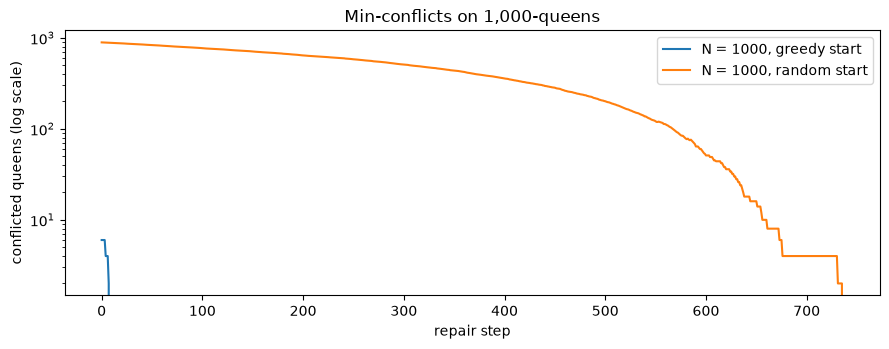

In [12]:
def min_conflicts_queens(n, rng, max_steps=100_000, greedy_init=True):
    rows = np.empty(n, dtype=np.int64)
    row_cnt = np.zeros(n, dtype=np.int64)          # queens per row
    d1 = np.zeros(2 * n - 1, dtype=np.int64)       # queens per "/" diagonal, index r + c
    d2 = np.zeros(2 * n - 1, dtype=np.int64)       # queens per "\" diagonal, index r - c + n - 1
    r_all = np.arange(n)

    def conflicts_in_column(c):
        # number of queens attacking each possible row of column c (column c itself must be empty)
        return row_cnt + d1[c:c + n] + d2[n - 1 - c:2 * n - 1 - c]

    def place(c, r, delta):
        row_cnt[r] += delta; d1[r + c] += delta; d2[r - c + n - 1] += delta

    for c in range(n):                             # initial complete assignment
        if greedy_init:
            conf = conflicts_in_column(c)
            best = np.flatnonzero(conf == conf.min())
            r = int(best[rng.integers(len(best))])
        else:
            r = int(rng.integers(n))
        rows[c] = r; place(c, r, +1)

    cols = np.arange(n)
    history = []
    for step in range(max_steps):
        # conflicts of each queen = queens on its row and diagonals, minus itself (3 times)
        conf_each = row_cnt[rows] + d1[rows + cols] + d2[rows - cols + n - 1] - 3
        conflicted = np.flatnonzero(conf_each > 0)
        history.append(len(conflicted))
        if len(conflicted) == 0:
            return rows, step, history             # solved
        c = int(conflicted[rng.integers(len(conflicted))])   # a random conflicted variable
        place(c, rows[c], -1)                      # lift the queen
        conf = conflicts_in_column(c)
        best = np.flatnonzero(conf == conf.min())  # rows with the minimum number of conflicts
        r = int(best[rng.integers(len(best))])
        rows[c] = r; place(c, r, +1)
    return None, max_steps, history

def queens_valid(rows):
    # independent O(N) check: all rows distinct, all diagonals distinct
    n = len(rows)
    return (len(set(rows.tolist())) == n and len({r + c for c, r in enumerate(rows.tolist())}) == n
            and len({r - c for c, r in enumerate(rows.tolist())}) == n)

rows_out = []
histories = {}
for n, greedy in [(8, True), (100, True), (1000, True), (1000, False), (10_000, True)]:
    rng = np.random.default_rng(n)
    t0 = time.perf_counter()
    sol, steps, hist = min_conflicts_queens(n, rng, greedy_init=greedy)
    secs = time.perf_counter() - t0
    assert sol is not None and queens_valid(sol)
    histories[(n, greedy)] = hist
    rows_out.append({"N": n, "initial assignment": "greedy" if greedy else "random",
                     "conflicted queens at start": hist[0], "repair steps": steps, "seconds": round(secs, 2)})
display(pd.DataFrame(rows_out))

fig, ax = plt.subplots(figsize=(9, 3.6))
for key, label in [((1000, True), "N = 1000, greedy start"), ((1000, False), "N = 1000, random start")]:
    ax.plot(histories[key], label=label)
ax.set_yscale("log"); ax.set_xlabel("repair step"); ax.set_ylabel("conflicted queens (log scale)")
ax.set_title("Min-conflicts on 1,000-queens"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** Every result passed an independent $O(N)$ validity check (all rows and all diagonals distinct). From a greedy start, only a handful of queens are in conflict (6 of 1,000; 12 of 10,000), and a few repairs finish the job: 8 steps for $N = 1{,}000$ and 51 for $N = 10{,}000$. From a purely random start, 891 of the 1,000 queens are attacked at first and it needs 736 repairs, but the curve shows the number of conflicted queens falling steadily to zero.

**Complexity:** each repair step here costs $O(N)$ (vectorised), and the number of steps barely grows with $N$. Min-conflicts is incomplete (it can wander forever on an unsolvable or very tightly constrained problem), so it is used when solutions are plentiful. Compare backtracking, which is complete but would struggle with $N = 1000$.

## 7. Tree-structured CSPs (briefly)

*In plain words: if the constraint graph has no loops, a single sweep backwards and a single sweep forwards solve the problem.*

**Theorem:** if the constraint graph is a **tree** (connected, no cycles), the CSP can be solved in $O(n d^2)$ time, linear in the number of variables. Algorithm (AIMA Figure 6.11):
1. Pick a root and order the variables so that every parent comes before its children (**topological order**).
2. **Backward pass:** for $j = n$ down to 2, make the arc $\text{Parent}(X_j) \to X_j$ arc-consistent (remove parent values that no child value supports). If a domain empties, there is no solution.
3. **Forward pass:** give the root any value left, then give each child any value consistent with its parent. No backtracking is ever needed.

**Cutset conditioning:** for a general graph, find a small set $S$ of variables (a **cycle cutset**) whose removal leaves a tree. Try each assignment of $S$, prune the neighbours' domains, and solve the remaining tree: $O(d^{c} (n - c) d^2)$ for a cutset of size $c$. In Australia, removing **SA** leaves a chain WA-NT-Q-NSW-V plus the isolated T.

In [13]:
def tree_csp_solver(csp, domains=None):
    # solve a CSP whose constraint graph is a forest; returns a solution or None
    domains = {v: list((domains or csp.domains)[v]) for v in csp.variables}
    order, parent, seen = [], {}, set()
    for root in csp.variables:                          # handle every tree of the forest
        if root in seen:
            continue
        seen.add(root); parent[root] = None
        queue = deque([root])
        while queue:                                    # BFS gives a parent-before-child order
            v = queue.popleft(); order.append(v)
            for n in csp.neighbours[v]:
                if n not in seen:
                    seen.add(n); parent[n] = v; queue.append(n)
                elif n != parent[v] and parent.get(n) != v:
                    raise ValueError("the constraint graph has a cycle")
    for xj in reversed(order):                          # backward pass: make parent -> child consistent
        p = parent[xj]
        if p is not None:
            revise(csp, domains, p, xj)
            if not domains[p]:
                return None
    assignment = {}
    for xj in order:                                    # forward pass: no backtracking needed
        p = parent[xj]
        choices = [x for x in domains[xj] if p is None or csp.constraint(p, assignment[p], xj, x)]
        if not choices:
            return None
        assignment[xj] = choices[0]
    return assignment

# Check against brute force on random tree CSPs with random binary relations
check_rng = random.Random(3)
agree = 0
for trial in range(300):
    n, d = 7, 3
    variables = list(range(n))
    edges = [(i, check_rng.randrange(i)) for i in range(1, n)]          # a random tree
    allowed = {e: {(a, b) for a in range(d) for b in range(d) if check_rng.random() < 0.55} for e in edges}
    def rel(A, a, B, b, allowed=allowed):
        return (a, b) in allowed[(A, B)] if (A, B) in allowed else (b, a) in allowed[(B, A)]
    nbrs = {v: [] for v in variables}
    for a, b in edges:
        nbrs[a].append(b); nbrs[b].append(a)
    tcsp = CSP(variables, {v: list(range(d)) for v in variables}, nbrs, rel)
    sol = tree_csp_solver(tcsp)
    has_solution = any(tcsp.is_solution(dict(enumerate(vals))) for vals in itertools.product(range(d), repeat=n))
    assert (sol is not None) == has_solution and (sol is None or tcsp.is_solution(sol))
    agree += 1
print(f"tree solver agrees with brute force on {agree} random tree CSPs")

# Cutset conditioning on Australia with cutset {SA}
rest = [v for v in AUS_VARS if v != "SA"]
rest_edges = [(a, b) for a, b in AUS_EDGES if "SA" not in (a, b)]
rows = []
for colour in COLOURS:
    sub = make_map_csp(rest, rest_edges, COLOURS)
    doms = {v: [c for c in COLOURS if not (v in australia.neighbours["SA"] and c == colour)] for v in rest}
    sol = tree_csp_solver(sub, doms)
    full = {**sol, "SA": colour} if sol else None
    assert full is None or australia.is_solution(full)
    rows.append({"SA =": colour, "tree solver result": full})
display(pd.DataFrame(rows))

tree solver agrees with brute force on 300 random tree CSPs


,SA =,tree solver result
0,red,"{'WA': 'green', 'NT': 'blue', 'Q': 'green', 'N..."
1,green,"{'WA': 'red', 'NT': 'blue', 'Q': 'red', 'NSW':..."
2,blue,"{'WA': 'red', 'NT': 'green', 'Q': 'red', 'NSW'..."


**What just happened?** The tree solver agreed with brute force on 300 random tree-shaped CSPs (solvable or not), and every solution it returned was valid. Then **cutset conditioning** coloured Australia: for each colour of SA, the remaining graph is a forest, solved in linear time without backtracking.

## 8. Summary table

*In plain words: every method from this notebook side by side.*

| Method | Complete? | Time (worst case) | Space | Best for |
|---|---|---|---|---|
| Brute force (generate and test) | yes | $O(d^n)$ complete assignments | $O(n)$ | tiny problems, testing |
| Backtracking | yes | $O(d^n)$ | $O(n)$ plus domains | small problems |
| + MRV / degree / LCV | yes | $O(d^n)$, usually far less | same | almost always worth it |
| + Forward checking | yes | same | $O(nd)$ for domains | cheap look-ahead |
| + MAC (AC-3 at each node) | yes | same; $O(c\,d^3)$ per node | $O(nd + c)$ | hard puzzles (Sudoku, scheduling) |
| AC-3 alone (preprocessing) | no (may not decide) | $O(c\,d^3)$ | $O(c)$ | shrinking domains before search |
| Min-conflicts | no | depends; often nearly constant steps | $O(n)$ | huge problems with many solutions |
| Tree-CSP algorithm | yes (for trees) | $O(n d^2)$ | $O(nd)$ | tree-shaped constraint graphs |

($n$ variables, $d$ values per domain, $c$ binary constraints.)

## 🔗 How this connects to modern AI and real systems

- **Backtracking in DSA:** the recursive try-and-undo pattern is the same one used for permutations, subsets and N-Queens in [`../dsa/10_backtracking.ipynb`](../dsa/10_backtracking.ipynb). CSPs add *general-purpose* heuristics (MRV, LCV) and propagation (FC, AC-3).
- **Industrial solvers:** real scheduling, rostering and timetabling systems use constraint programming and SAT solvers that refine exactly these ideas: Google **OR-Tools** (CP-SAT), MiniZinc, Gecode, Choco, and SAT/SMT solvers such as Kissat and Z3. Integer linear programming is the other big family: [`../advanced_algorithms/05_linear_and_integer_programming.ipynb`](../advanced_algorithms/05_linear_and_integer_programming.ipynb).
- **Schedulers everywhere:** the Kubernetes scheduler first *filters* nodes that violate hard constraints (enough CPU and memory, affinity rules) and then *scores* the rest by soft preferences: hard constraints plus a preference ordering, just like a CSP with soft constraints. Airline crew rostering, hospital shift planning and exam timetabling are classic CSP/optimisation applications.
- **LLMs:** constrained decoding (forcing output to match a JSON schema or a grammar) removes tokens that would break the constraints at every step, which is forward checking on the next token: see [`08_LLM/17_structured_outputs.ipynb`](../../08_LLM/17_structured_outputs.ipynb). LLM agents are also often paired with a solver: the LLM writes the constraints, the solver finds the answer.
- **Route planning and scheduling case study:** [`11_industry_route_planning_and_scheduling.ipynb`](11_industry_route_planning_and_scheduling.ipynb).

The optional cell below shows how the same Sudoku looks in OR-Tools' CP-SAT solver, if you have it installed (`pip install ortools`). The lesson does not depend on it.

In [14]:
try:
    from ortools.sat.python import cp_model           # optional: not required for this notebook
    model = cp_model.CpModel()
    X = {(r, c): model.NewIntVar(1, 9, f"x{r}{c}") for r in range(9) for c in range(9)}
    for i, ch in enumerate(HARD_SUDOKU):
        if ch != "0":
            model.Add(X[(i // 9, i % 9)] == int(ch))
    for k in range(9):
        model.AddAllDifferent([X[(k, c)] for c in range(9)])       # global Alldiff constraints
        model.AddAllDifferent([X[(r, k)] for r in range(9)])
        model.AddAllDifferent([X[(3 * (k // 3) + i, 3 * (k % 3) + j)] for i in range(3) for j in range(3)])
    solver = cp_model.CpSolver()
    status = solver.Solve(model)
    ortools_sol = {v: solver.Value(x) for v, x in X.items()}
    print("OR-Tools CP-SAT agrees with our solver:", ortools_sol == hard_sol)
except ImportError:
    print("OR-Tools is not installed; skipping this optional comparison (pip install ortools to try it).")

OR-Tools is not installed; skipping this optional comparison (pip install ortools to try it).


## Recap

- A **CSP** = variables + domains + constraints (unary, binary, global). A solution is a complete, consistent assignment. The **constraint graph** shows the structure.
- **Backtracking search** assigns one variable at a time and undoes choices that break a constraint: complete, worst case $O(d^n)$.
- **MRV** (fail-first) and the **degree heuristic** choose variables; **LCV** (fail-last) chooses values.
- **Forward checking** prunes neighbours' domains after each assignment; **AC-3** enforces arc consistency in $O(c\,d^3)$; **MAC** runs AC-3 inside the search. Arc consistency is not the same as solvability.
- On our benchmarks, MRV and inference turn impossible searches into tiny ones; MAC + MRV + LCV solved the hard Sudoku with the fewest assignments.
- **Min-conflicts** repairs a complete assignment and solved 1,000- and 10,000-queens in a few dozen steps from a greedy start.
- **Tree-structured** CSPs are solvable in $O(n d^2)$; **cutset conditioning** reduces general graphs to trees.

## Practice problems

**1. (Easy, conceptual)** How many binary "≠" constraints does Sudoku have, and why?

<details><summary>Show solution</summary>

Each cell has 20 peers (8 in its row, 8 in its column, 4 more in its box). Counting each pair once: $81 \times 20 / 2 = 810$. (Equivalently, 27 Alldiff units of 9 cells give $27 \times 36 = 972$ pairs, but row and box (or column and box) units share pairs: $972 - 162 = 810$.)

```python
assert sudoku_csp(EASY_SUDOKU).n_binary_constraints() == 810
```
</details>

**2. (Easy, conceptual)** Why is MRV called "fail-first", and why is LCV called "fail-last"?

<details><summary>Show solution</summary>

MRV picks the variable most likely to cause a failure soon (fewest values left), so dead ends are discovered near the top of the tree where they prune the most. LCV orders the *values* of the chosen variable so that the one leaving the most options for others is tried first, making failure as unlikely (late) as possible. Variables all need values eventually; values only need one success.
</details>

**3. (Medium, by hand + code)** Two variables $X, Y$ with domains $\{1, 2, 3\}$ and the constraint $X < Y$. Run AC-3 by hand. Then check with the notebook's `ac3`.

<details><summary>Show solution</summary>

Arc $X \to Y$: $X = 3$ has no $Y > 3$, so remove it: $D_X = \{1, 2\}$. Arc $Y \to X$: $Y = 1$ has no $X < 1$, so remove it: $D_Y = \{2, 3\}$. Re-checking finds nothing else.

```python
lt = CSP(["X", "Y"], {"X": [1, 2, 3], "Y": [1, 2, 3]}, {"X": ["Y"], "Y": ["X"]},
         lambda A, a, B, b: a < b if A == "X" else b < a)
doms = {"X": [1, 2, 3], "Y": [1, 2, 3]}
assert ac3(lt, doms) and doms == {"X": [1, 2], "Y": [2, 3]}
print(doms)
```
</details>

**4. (Medium, coding)** Show that Australia cannot be coloured with two colours, using `backtracking_search`. Which part of the constraint graph makes it impossible?

<details><summary>Show solution</summary>

```python
sol, st = backtracking_search(make_map_csp(AUS_VARS, AUS_EDGES, ["red", "green"]), inference="fc")
print(sol, dict(st))
assert sol is None
```
WA, NT and SA are mutual neighbours (a triangle, a 3-clique). A triangle needs 3 colours, so no 2-colouring exists. In general, a graph is 2-colourable exactly when it has no odd cycle.
</details>

**5. (Medium, coding)** Use `count_solutions` to count the solutions of the 6-queens and 9-queens problems.

<details><summary>Show solution</summary>

```python
print(count_solutions(queens_csp(6)), count_solutions(queens_csp(9)))
assert count_solutions(queens_csp(6)) == 4 and count_solutions(queens_csp(9)) == 352
```
6-queens has only 4 solutions (fewer than 5-queens' 10!), and 9-queens has 352.
</details>

**6. (Hard, coding)** Write a *general* `min_conflicts(csp, max_steps, rng)` that works with the notebook's `CSP` class, and use it to solve 50-queens and the Australia map.

<details><summary>Show solution</summary>

```python
def min_conflicts(csp, max_steps, rng):
    current = {v: rng.choice(csp.domains[v]) for v in csp.variables}       # random complete assignment
    def n_conflicts(var, val):
        return sum(not csp.constraint(var, val, n, current[n]) for n in csp.neighbours[var])
    for _ in range(max_steps):
        conflicted = [v for v in csp.variables if n_conflicts(v, current[v]) > 0]
        if not conflicted:
            return current
        var = rng.choice(conflicted)
        scores = {val: n_conflicts(var, val) for val in csp.domains[var]}
        best = min(scores.values())
        current[var] = rng.choice([val for val, s in scores.items() if s == best])
    return None

rng = random.Random(0)
q50 = queens_csp(50)
sol = min_conflicts(q50, 2000, rng)
assert sol is not None and q50.is_solution(sol)
sol = min_conflicts(australia, 1000, rng)
assert australia.is_solution(sol)
print("min-conflicts solved 50-queens and Australia")
```
</details>

**7. (Hard, conceptual)** A CSP has $n = 100$ variables with $d = 10$ values. Compare the worst case of plain backtracking with the tree-CSP algorithm if the constraint graph is a tree, and with cutset conditioning if removing $c = 5$ variables leaves a tree.

<details><summary>Show solution</summary>

Backtracking: up to $d^n = 10^{100}$ complete assignments. Tree algorithm: $O(n d^2) = 100 \times 100 = 10^4$ steps. Cutset conditioning: $d^c$ cutset assignments, each followed by an $O((n - c) d^2)$ tree solve: $10^5 \times 95 \times 100 \approx 10^9$ steps: large but feasible, and astronomically smaller than $10^{100}$. Structure matters as much as raw size.
</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed. (2020), Chapter 6 "Constraint Satisfaction Problems".
- Mackworth, "Consistency in Networks of Relations", *Artificial Intelligence* 8 (1977), the origin of AC-3; Minton, Johnston, Philips & Laird, "Minimizing conflicts: a heuristic repair method for constraint satisfaction and scheduling problems", *Artificial Intelligence* 58 (1992).
- Rossi, van Beek & Walsh (eds.), *Handbook of Constraint Programming* (2006).
- Free online: Peter Norvig's essay "[Solving Every Sudoku Puzzle](https://norvig.com/sudoku.html)" (constraint propagation + search in a page of Python) and the [OR-Tools constraint programming guide](https://developers.google.com/optimization/cp).

## Next notebook

[`07_knowledge_representation_and_logic.ipynb`](07_knowledge_representation_and_logic.ipynb): representing knowledge with propositional and first-order logic, and reasoning with it. (SAT, the satisfiability problem met there, is itself a CSP with Boolean variables.)

In [15]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.1f} s")

Notebook finished in 12.1 s
